# Calibrated spatial pH in living roots

## 1. Problem

We invert a nonlinear fluorescence response into 43 complete spatial pH maps. Every figure reconstructs the actual bound ratio observations with local numerical mathematics. Independent root samples at pH 5 and 7 calibrate the experiment's ratio scale; the target roots never calibrate themselves. Frozen original Ratio2pH results are explicitly identified comparisons, not chemical truth.

The task preserves the published response/sensitivity and pharmacological spatial-map comparisons. A material limitation is that the paper quantified manually selected late-meristem cells, while no corresponding ROI files were supplied. Here we evaluate the entire measured field. Whole-field treatment summaries must not be called reproductions of the paper's ROI effect sizes or significance categories.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,platform,tempfile
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,calibration_levels,valid_pixels,GROUPS,PIXEL_WIDTH_UM
from src.physics_model import normalize_ratio,fluorescence_response,invert_response,TOP,BOTTOM,EPS
from src.solvers import reconstruct,invert_image
from src.visualization import agreement,ph_image
FIG=Path(os.environ.get('IMAGING_REVIEW_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging-101-root-ph-review')));FIG.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':100,'savefig.dpi':150,'svg.fonttype':'none','pdf.fonttype':42})
started=time.perf_counter();figure_sources=[]
def export(fig,name,arrays,description):
    for ext in ['png','svg','pdf']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight')
    np.savez_compressed(FIG/(name+'.npz'),**arrays)
    row={'figure':name,'description':description,'numeric_keys':list(arrays),'files':{ext:{'file':name+'.'+ext,'sha256':hashlib.sha256((FIG/(name+'.'+ext)).read_bytes()).hexdigest()} for ext in ['png','svg','pdf','npz']}}
    (FIG/(name+'.json')).write_text(json.dumps(row,indent=2),encoding='utf-8');figure_sources.append(row)
    plt.show();plt.close(fig)
environment={'python':sys.version,'executable':sys.executable,'platform':platform.platform(),'numpy':np.__version__,'matplotlib':matplotlib.__version__,'OMP_NUM_THREADS':os.environ.get('OMP_NUM_THREADS')}
print(json.dumps(environment,indent=2))

{
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "platform": "Windows-10-10.0.26200-SP0",
  "numpy": "2.4.6",
  "matplotlib": "3.11.1",
  "OMP_NUM_THREADS": "1"
}


## 2. Data

The public inputs contain 43 native 1024-square ratio images, nine low-calibration and eight high-calibration root images. NaN and zero target ratios are unavailable under the original rule; every other finite ratio, including negative ratios, is retained. Native spacing is 0.18037518037518038 micrometre from the author TIFF calibration. Four treatment groups are present: solvent control (12), DCCD (12), fusicoccin (8) and IAA (11).

There is an explicit wavelength-description discrepancy: the paper's generic label and in-vitro characterization say 465/405 nm, while microscopy Methods and all six native LIF acquisition XML headers identify 458/405 nm. We retain the supplied ratio observations and same-experiment calibrations without inventing a wavelength correction. The inverse starts from author-processed ratios, not raw fluorescence channels.

Calibration lower/high: 0.3933395155239811 1.875376803966015 measured pixels: 1346431 roots: 43
Minimum NCC: 0.9999999999999998 maximum NRMSE: 0.0


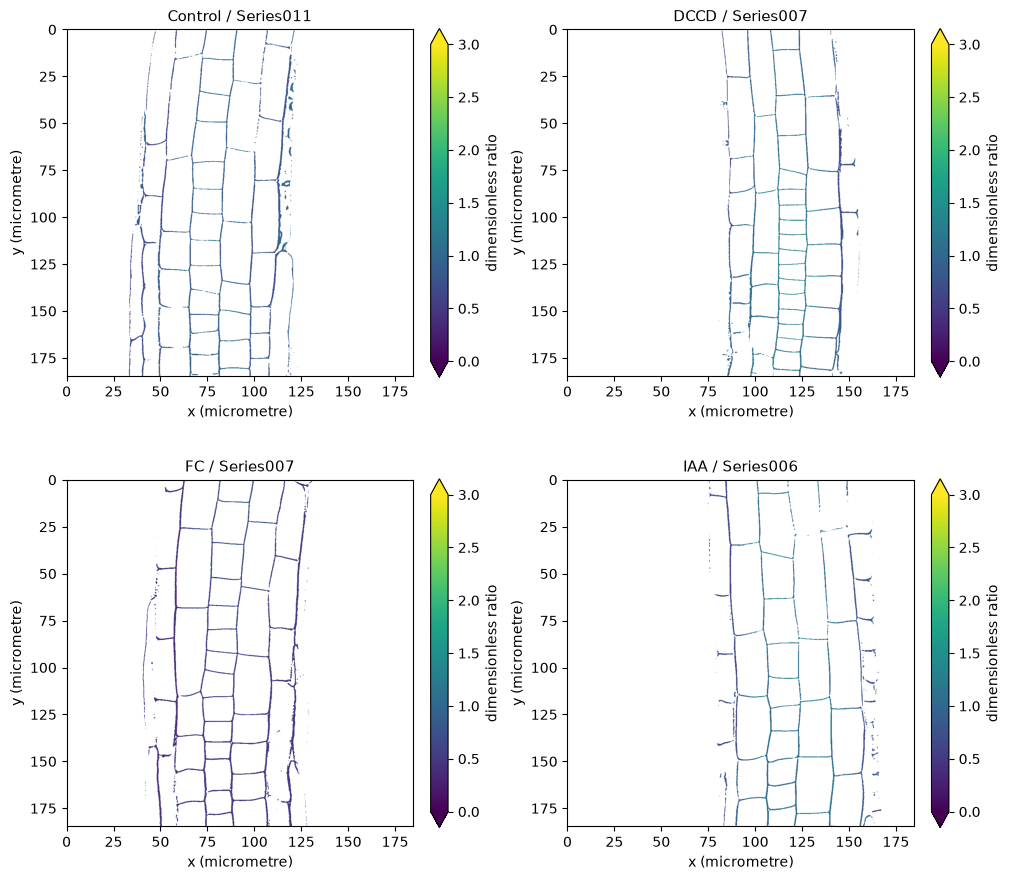

In [2]:
ratios,low,high=load_observations(ROOT/'data/raw_data.npz')
ph,lower,upper,clipping_rates=reconstruct(ratios,low,high)
_,_,low_means,high_means=calibration_levels(low,high)
masks=valid_pixels(ratios)
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as a:original=a['reconstruction'][0]
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as a:original_root_means=a['per_root_mean_pH']
metrics=[agreement(a,b,m) for a,b,m in zip(ph,original,masks)]
root_means=np.array([a[m].mean(dtype=float) for a,m in zip(ph,masks)])
root_ratio_means=np.array([a[m].mean(dtype=float) for a,m in zip(ratios,masks)])
# Fixed author's representative Series: control011, DCCD007, FC007, IAA006.
examples=[10,18,30,37];labels=['Control / Series011','DCCD / Series007','FC / Series007','IAA / Series006']
print('Calibration lower/high:',lower,upper,'measured pixels:',masks.sum(),'roots:',len(ph))
print('Minimum NCC:',min(x['ncc'] for x in metrics),'maximum NRMSE:',max(x['nrmse'] for x in metrics))
fig,axs=plt.subplots(2,2,figsize=(10,9),layout='constrained')
for ax,i,label in zip(axs.ravel(),examples,labels):ph_image(ax,ratios[i],masks[i],label,(0.,3.),unit='dimensionless ratio')
export(fig,'01_native_ratio_maps',{'ratios':ratios[examples],'valid_masks':masks[examples],'root_indices':np.array(examples)},'Original native complete-FOV ratio images; fixed author representative Series, no fitted-value masks.')

## 3. Physics

Protonation changes indicator fluorescence. For ratio $R$ and independent reference levels $L,H$, normalized response $q=(R-L)/(H-L)$ follows

$$q=B+\frac{T-B}{1+10^{h(c-p)}}.$$

Here $p$ is pH, $B=-0.0295$ and $T=1.1171$ are response asymptotes, $h=1.2133$ is the slope and $c=6.2110$ the inflection pH. These precise coefficients are from the released calibration, separate from the target roots. The direct inverse is

$$p=c-\frac{\ln((T-B)/(q-B)-1)}{h\ln(10)}.$$

The natural logarithm is divided by $\ln(10)$ to match the base-ten equilibrium response. Near an asymptote the inverse is ill conditioned. The plot below actively propagates a normalized-ratio perturbation of 0.01 as in the paper's sensitivity experiment. This is a specified perturbation, not a measured noise calibration for these images.

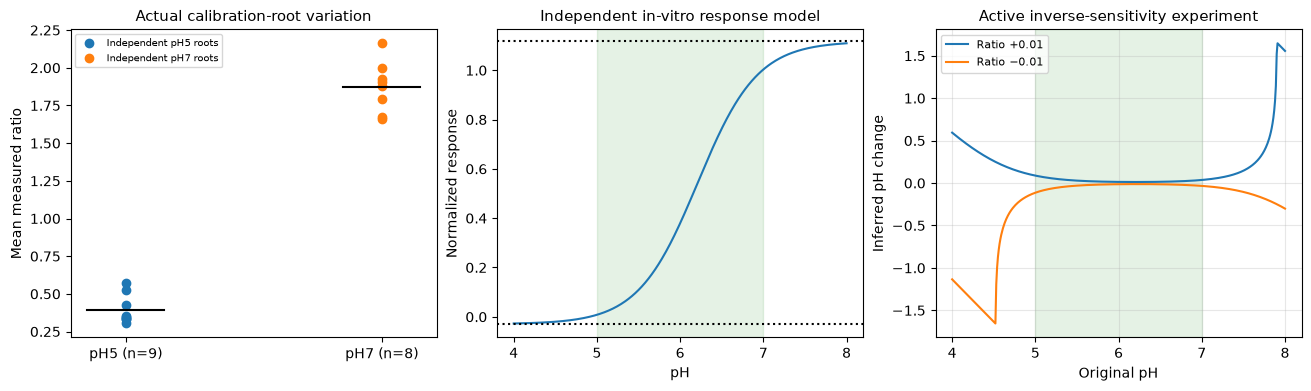

In [3]:
grid=np.linspace(4.,8.,401);response=fluorescence_response(grid)
plus,_=invert_response(response+.01);minus,_=invert_response(response-.01)
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
ax[0].plot(np.zeros(len(low_means)),low_means,'o',label='Independent pH5 roots');ax[0].plot(np.ones(len(high_means)),high_means,'o',label='Independent pH7 roots')
ax[0].plot([-.15,.15],[lower]*2,'k-');ax[0].plot([.85,1.15],[upper]*2,'k-');ax[0].set(xticks=[0,1],xticklabels=['pH5 (n=9)','pH7 (n=8)'],ylabel='Mean measured ratio',title='Actual calibration-root variation');ax[0].legend(fontsize=7)
ax[1].plot(grid,response);ax[1].axhline(BOTTOM,color='k',ls=':');ax[1].axhline(TOP,color='k',ls=':');ax[1].axvspan(5,7,alpha=.1,color='green');ax[1].set(xlabel='pH',ylabel='Normalized response',title='Independent in-vitro response model')
ax[2].plot(grid,plus-grid,label='Ratio +0.01');ax[2].plot(grid,minus-grid,label='Ratio −0.01');ax[2].axvspan(5,7,alpha=.1,color='green');ax[2].set(xlabel='Original pH',ylabel='Inferred pH change',title='Active inverse-sensitivity experiment');ax[2].legend(fontsize=8);ax[2].grid(alpha=.3)
export(fig,'02_calibration_and_physics',{'low_root_means':low_means,'high_root_means':high_means,'pH_grid':grid,'forward_response':response,'plus_response_inferred_pH':plus,'minus_response_inferred_pH':minus},'Actual independent-root calibration means and freshly computed sigmoid/sensitivity; green band is calibrated pH5–7, not output clamping.')

## 4. Method

We compute a NaN-ignoring mean for each independent reference image, including finite zeros, then average reference roots equally. This matches original ImageJ statistics and the source's manual calibration mode. Normalize each measured target pixel, clip only the normalized response into $[B+10^{-4},T-10^{-4}]$, evaluate the direct inverse and store float32 as in the original FloatProcessor. NaN/zero input pixels become zero output padding. There is no optimizer, iteration, learned target calibration or spatial interpolation.

The display range 5–7 does not change any array value. Colorbar extensions expose values outside it. Saturation and out-of-calibration pixels remain in every image's score. The comparison below uses the actual unchanged original Jython/ImageJ run on these exact observations and calibration levels, not cached paper images.

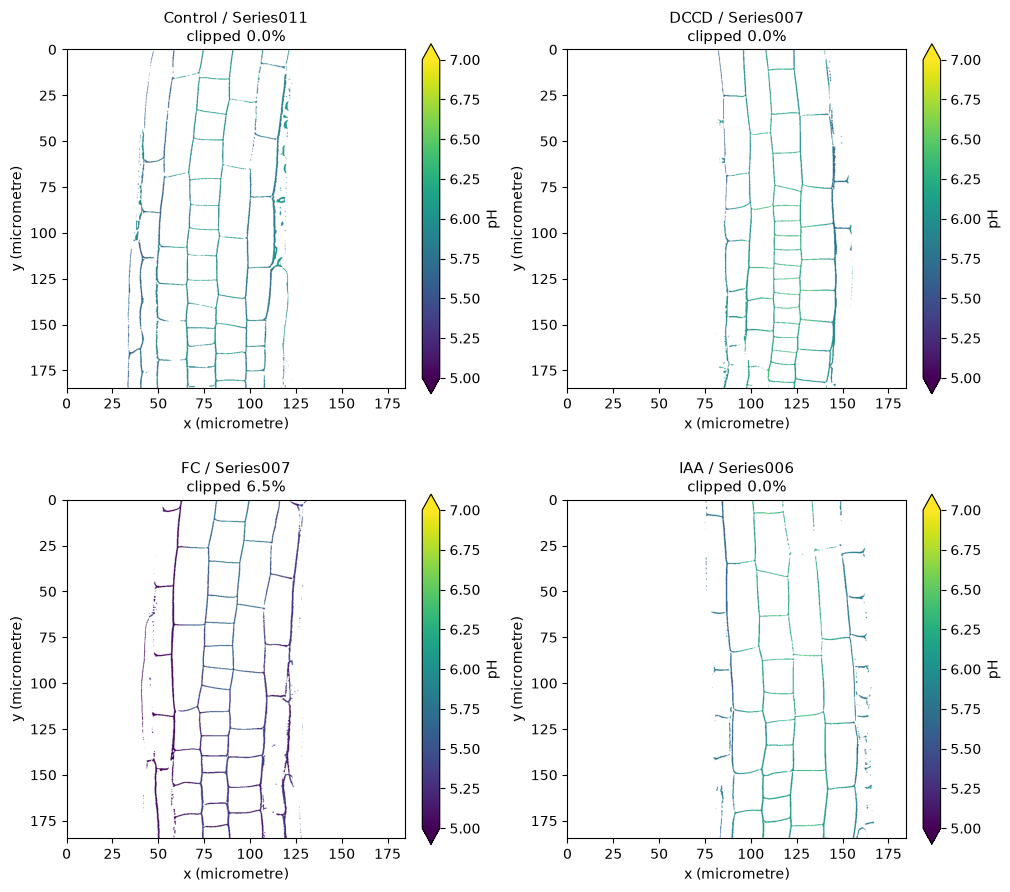

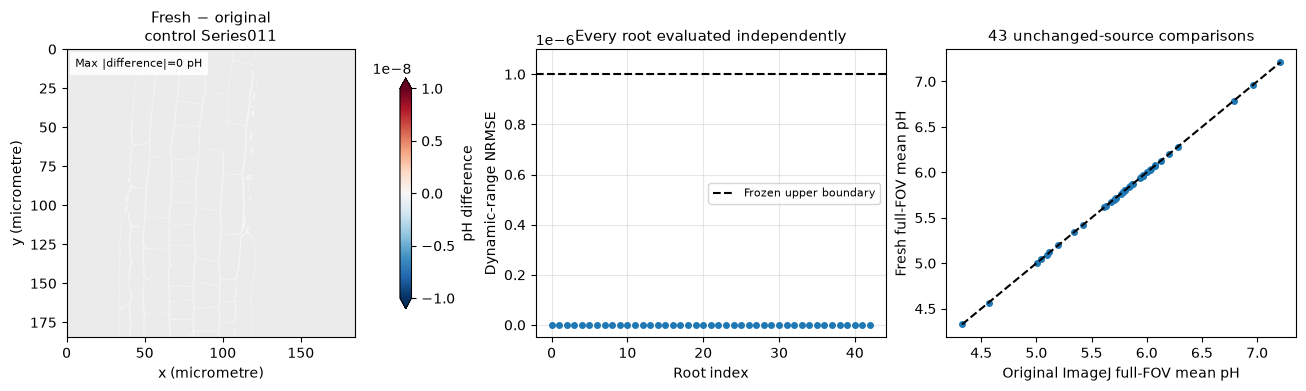

In [4]:
fig,axs=plt.subplots(2,2,figsize=(10,9),layout='constrained')
for ax,i,label in zip(axs.ravel(),examples,labels):
    ph_image(ax,ph[i],masks[i],label+'\n'+f'clipped {clipping_rates[i]*100:.1f}%')
export(fig,'03_fresh_pH_maps',{'fresh_pH':ph[examples],'valid_masks':masks[examples],'root_indices':np.array(examples),'clipping_fraction':clipping_rates[examples]},'Fresh full-FOV pH maps using the original nonlinear inverse, with all saturation retained and common display range.')

fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
diff=ph[examples[0]].astype(float)-original[examples[0]]
limit=max(float(abs(diff[masks[examples[0]]]).max()),1e-8)
ph_image(ax[0],diff,masks[examples[0]],'Fresh − original\ncontrol Series011',(-limit,limit),'RdBu_r',unit='pH difference')
ax[0].set_facecolor('.92');ax[0].text(.03,.97,f'Max |difference|={abs(diff[masks[examples[0]]]).max():.3g} pH',transform=ax[0].transAxes,va='top',fontsize=8,bbox={'facecolor':'white','edgecolor':'none','alpha':.9})
nrmses=np.array([x['nrmse'] for x in metrics]);ax[1].plot(range(43),nrmses,'o',ms=4);ax[1].axhline(1e-6,color='k',ls='--',label='Frozen upper boundary');ax[1].set_ylim(-.05e-6,1.1e-6);ax[1].set(xlabel='Root index',ylabel='Dynamic-range NRMSE',title='Every root evaluated independently');ax[1].ticklabel_format(axis='y',style='sci',scilimits=(0,0));ax[1].legend(fontsize=8);ax[1].grid(alpha=.3)
ax[2].plot(original_root_means,root_means,'o',ms=4);lim=[root_means.min(),root_means.max()];ax[2].plot(lim,lim,'k--');ax[2].set(xlabel='Original ImageJ full-FOV mean pH',ylabel='Fresh full-FOV mean pH',title='43 unchanged-source comparisons')
export(fig,'04_original_parity',{'fresh_representative':ph[examples[0]],'original_representative':original[examples[0]],'difference':diff,'valid_mask':masks[examples[0]],'per_image_ncc':np.array([x['ncc'] for x in metrics]),'per_image_nrmse':nrmses,'original_root_means':original_root_means,'fresh_root_means':root_means},'Actual upstream/fresh numerical comparisons on the same observations; difference display minimum scale1e-8 pH, actual values preserved.')

## 5. Results

The four treatment groups are preserved. Each dot below is a complete measured root field, not a biological replicate invented from individual pixels. The original paper's historical selected-ROI mean changes were approximately DCCD +0.3, FC −0.6 and IAA +0.35 pH units. Those ROI-restricted measurements are **not reproduced full-field measurements here**: the released ROI selections are unavailable. We show actual whole-field distributions and exact original-code agreement, without copying historical significance letters.

Large apparent pH excursions are not silently discarded. They expose saturation, tissue/background preprocessing and the limits of applying a narrow-range calibration to every finite ratio pixel. These fields are conditional method estimates, not independently measured proton-concentration truth.

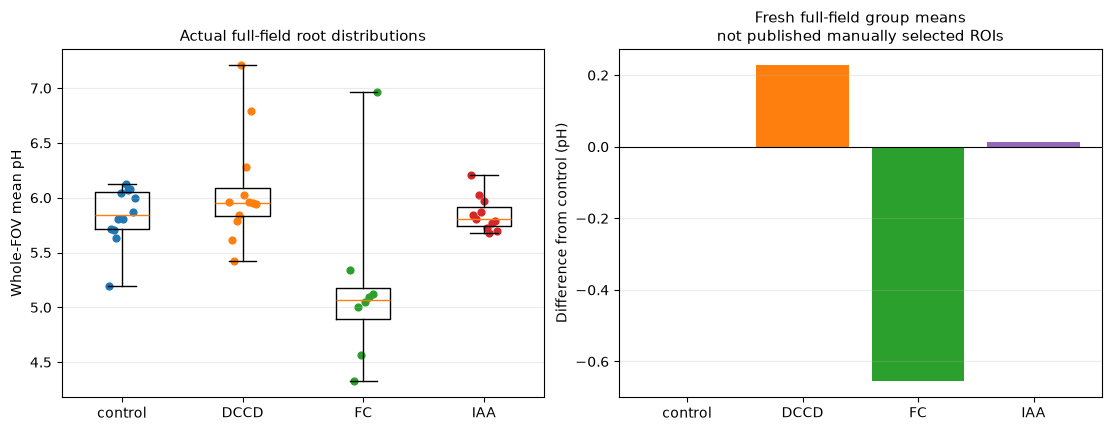

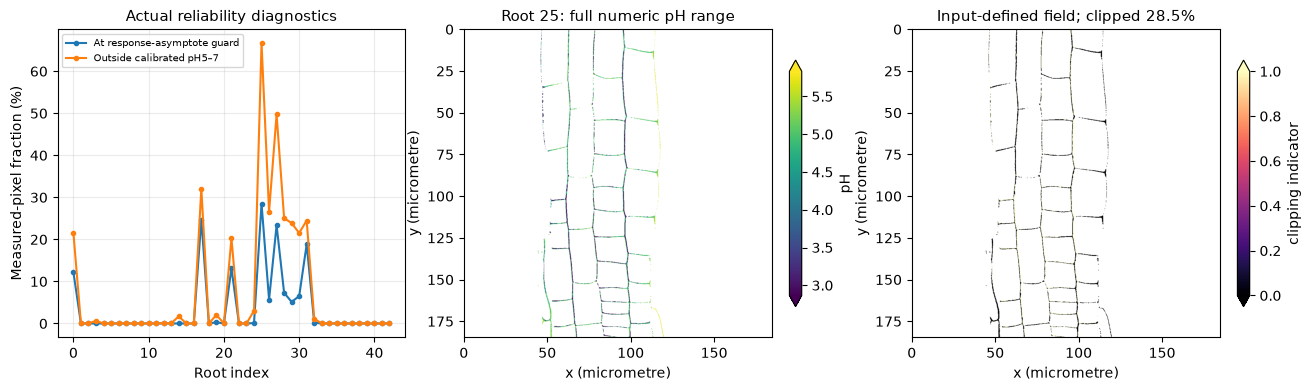

In [5]:
names=['control','DCCD','FC','IAA'];indices=[np.flatnonzero(np.array(GROUPS)==name) for name in names]
fig,ax=plt.subplots(1,2,figsize=(11,4.2),layout='constrained')
ax[0].boxplot([root_means[ii] for ii in indices],tick_labels=names,whis=(0,100),showfliers=False)
for j,ii in enumerate(indices):ax[0].scatter(j+1+np.linspace(-.11,.11,len(ii)),root_means[ii],s=24,label=f'{names[j]} n={len(ii)}')
ax[0].set(ylabel='Whole-FOV mean pH',title='Actual full-field root distributions');ax[0].grid(axis='y',alpha=.25)
group_means=np.array([root_means[ii].mean() for ii in indices]);deltas=group_means-group_means[0]
ax[1].bar(names,deltas,color=['gray','tab:orange','tab:green','tab:purple']);ax[1].axhline(0,color='k',lw=.8);ax[1].set(ylabel='Difference from control (pH)',title='Fresh full-field group means\nnot published manually selected ROIs');ax[1].grid(axis='y',alpha=.25)
export(fig,'05_treatment_comparison',{'per_root_mean_pH':root_means,'group_ids':np.array([names.index(x) for x in GROUPS]),'group_mean_pH':group_means,'difference_from_control':deltas},'All43 actual native root fields, all four drug groups; full-FOV estimand explicitly differs from historical manually selected late-meristem ROI.')

outside=np.array([np.mean((a[m]<5)|(a[m]>7)) for a,m in zip(ph,masks)])
worst=int(np.argmax(clipping_rates));_,_,clipmask=invert_image(ratios[worst],lower,upper)
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
ax[0].plot(range(43),clipping_rates*100,'o-',ms=3,label='At response-asymptote guard');ax[0].plot(range(43),outside*100,'o-',ms=3,label='Outside calibrated pH5–7');ax[0].set(xlabel='Root index',ylabel='Measured-pixel fraction (%)',title='Actual reliability diagnostics');ax[0].legend(fontsize=7);ax[0].grid(alpha=.25)
ph_image(ax[1],ph[worst],masks[worst],f'Root {worst}: full numeric pH range',(float(ph[worst][masks[worst]].min()),float(ph[worst][masks[worst]].max())))
ph_image(ax[2],clipmask.astype(float),masks[worst],f'Input-defined field; clipped {clipping_rates[worst]*100:.1f}%',(0,1),'magma',unit='clipping indicator')
export(fig,'06_saturation_and_range',{'per_root_clipped_fraction':clipping_rates,'per_root_outside_calibration_fraction':outside,'worst_root_index':np.array(worst),'worst_root_ph':ph[worst],'worst_root_mask':masks[worst],'worst_root_clipmask':clipmask},'Source clipping and out-of-calibration values remain scored; worst root shown without quality masking.')

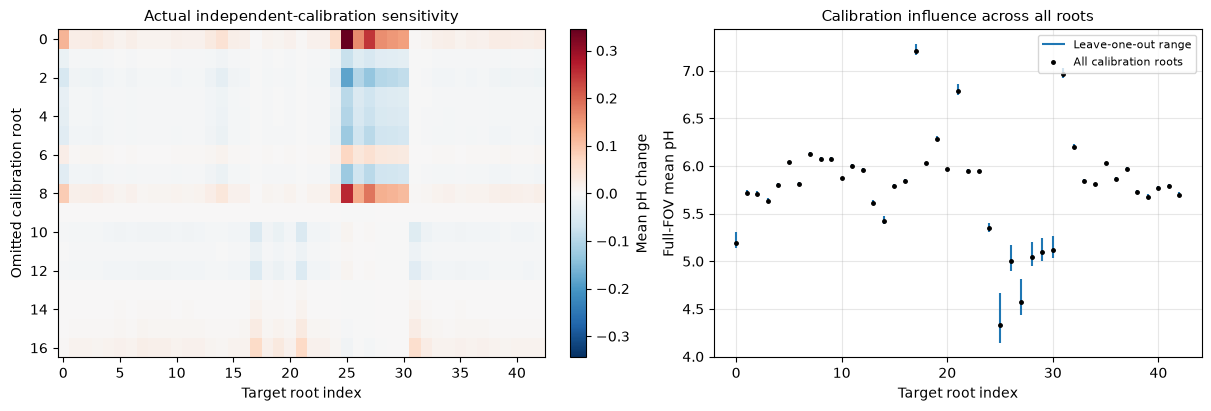

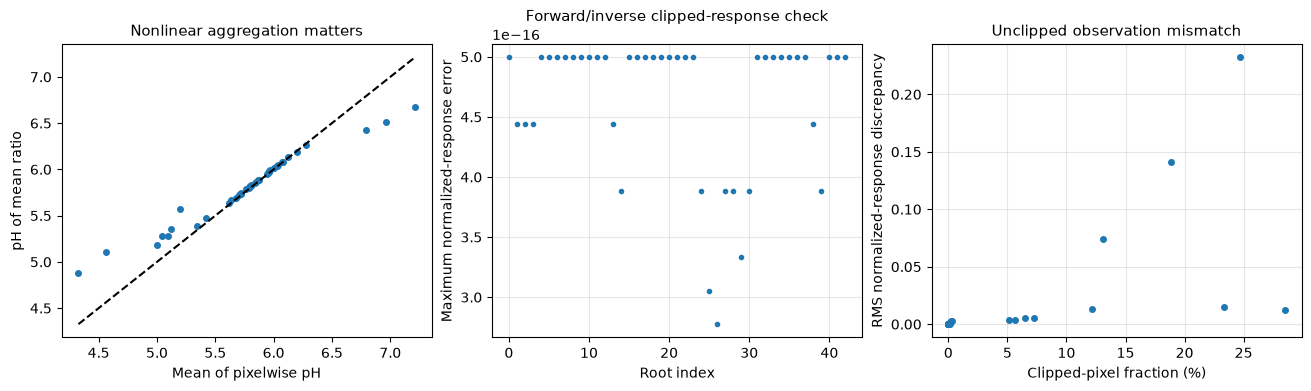

In [6]:
# Actual leave-one-calibration-root-out reconstructions; retain all target pixels.
calibration_schemes=[]
for i in range(len(low_means)):calibration_schemes.append((float(np.delete(low_means,i).mean()),upper))
for i in range(len(high_means)):calibration_schemes.append((lower,float(np.delete(high_means,i).mean())))
jackknife=np.empty((len(calibration_schemes),43))
for j,(lo,hi) in enumerate(calibration_schemes):
    for i in range(43):
        values,_=invert_response(normalize_ratio(ratios[i][masks[i]],lo,hi))
        jackknife[j,i]=values.astype(np.float32).mean(dtype=float)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
im=ax[0].imshow(jackknife-root_means[None],aspect='auto',cmap='RdBu_r',vmin=-abs(jackknife-root_means).max(),vmax=abs(jackknife-root_means).max(),rasterized=True)
plt.colorbar(im,ax=ax[0],label='Mean pH change');ax[0].set(xlabel='Target root index',ylabel='Omitted calibration root',title='Actual independent-calibration sensitivity')
lo=jackknife.min(axis=0);hi=jackknife.max(axis=0)
ax[1].vlines(range(43),lo,hi,color='tab:blue',label='Leave-one-out range');ax[1].plot(range(43),root_means,'k.',ms=5,label='All calibration roots');ax[1].set(xlabel='Target root index',ylabel='Full-FOV mean pH',title='Calibration influence across all roots');ax[1].legend(fontsize=8);ax[1].grid(alpha=.3)
export(fig,'07_calibration_sensitivity',{'calibration_levels':np.array(calibration_schemes),'jackknife_per_root_mean_pH':jackknife,'primary_root_mean_pH':root_means},'Seventeen actual independent-root leave-one-out calibration inversions, all43 target roots; sensitivity range is not a confidence interval.')

# Nonlinearity and observation consistency use actual bound ratios.
mean_then_inverse=np.array([invert_response(normalize_ratio(v,lower,upper))[0].item() for v in root_ratio_means])
roundtrip_max=[];unclipped_errors=[]
for image,valid in zip(ratios,masks):
    q=normalize_ratio(image[valid],lower,upper);inverse,clipped=invert_response(q)
    predicted=fluorescence_response(inverse);target=np.clip(q,BOTTOM+EPS,TOP-EPS)
    roundtrip_max.append(np.max(abs(predicted-target)))
    unclipped_errors.append(np.sqrt(np.mean((predicted-q)**2)))
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
ax[0].plot(root_means,mean_then_inverse,'o',ms=4);lim=[min(root_means.min(),mean_then_inverse.min()),max(root_means.max(),mean_then_inverse.max())];ax[0].plot(lim,lim,'k--');ax[0].set(xlabel='Mean of pixelwise pH',ylabel='pH of mean ratio',title='Nonlinear aggregation matters')
ax[1].plot(range(43),roundtrip_max,'o',ms=3);ax[1].set(xlabel='Root index',ylabel='Maximum normalized-response error',title='Forward/inverse clipped-response check');ax[1].ticklabel_format(axis='y',style='sci',scilimits=(0,0));ax[1].grid(alpha=.3)
ax[2].plot(clipping_rates*100,unclipped_errors,'o',ms=4);ax[2].set(xlabel='Clipped-pixel fraction (%)',ylabel='RMS normalized-response discrepancy',title='Unclipped observation mismatch');ax[2].grid(alpha=.3)
export(fig,'08_nonlinearity_and_residual',{'mean_pixelwise_pH':root_means,'pH_of_mean_ratio':mean_then_inverse,'forward_inverse_clipped_max_error':np.array(roundtrip_max),'unclipped_observation_response_rms':np.array(unclipped_errors),'clipping_fraction':clipping_rates},'Actual image aggregation noncommutativity and forward consistency; original unclipped mismatch explicitly reflects asymptote guard, not a noise-weighted likelihood.')

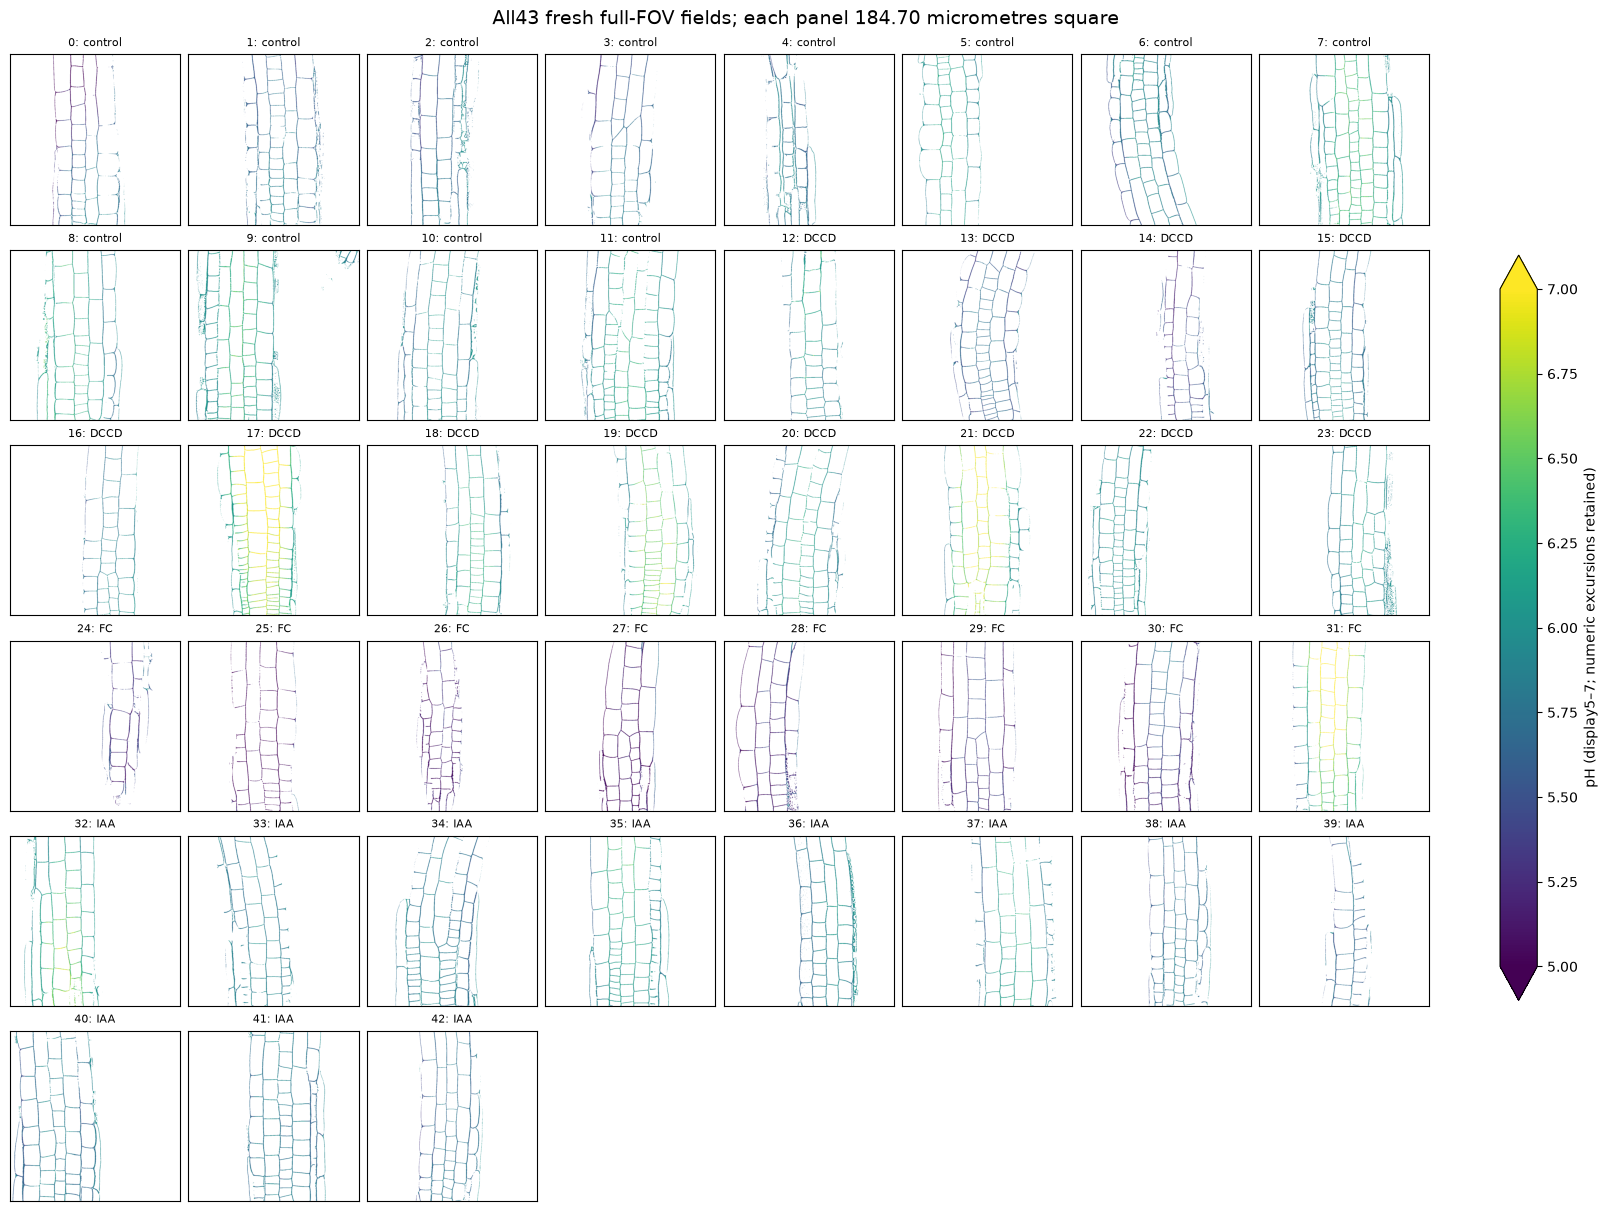

In [7]:
fig,axs=plt.subplots(6,8,figsize=(16,12),layout='constrained')
for i,ax in enumerate(axs.ravel()):
    if i>=43:ax.set_visible(False);continue
    im=ax.imshow(np.ma.array(ph[i],mask=~masks[i]),cmap='viridis',vmin=5,vmax=7,rasterized=True)
    ax.set_title(f'{i}: {GROUPS[i]}',fontsize=8);ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=[a for a in axs.ravel() if a.get_visible()],label='pH (display5–7; numeric excursions retained)',shrink=.65,extend='both')
fig.suptitle(f'All43 fresh full-FOV fields; each panel {1024*PIXEL_WIDTH_UM:.2f} micrometres square',fontsize=14)
export(fig,'09_all_root_atlas',{'all_fresh_pH':ph,'all_valid_masks':masks,'group_ids':np.array([names.index(x) for x in GROUPS])},'Complete freshly reconstructed cohort atlas, native pixels preserved; identical full FOV and display scale for every root.')

## 6. Conclusion

The local direct inverse reproduces original ImageJ/Jython output on all 43 native root fields and exactly recovers the independent ImageJ calibration means. Independent chemical-response checks verify the logarithm convention and monotonic inverse. Actual calibration-root sensitivity, nonlinear aggregation, saturation and whole-field pharmacological distributions are all exposed.

The benchmark validates a specified calibrated pH estimate, not an independently characterized chemical truth. Values near response asymptotes or outside pH5–7 have reduced reliability, full-field averages differ from published manually selected cell ROIs, and the original microscopy/in-vitro excitation descriptions differ. No saturation-dependent quality mask, invented ROI or historical result is substituted for a fresh map.

In [8]:
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge)
output=ROOT/'output/reconstruction.npz';np.savez_compressed(output,reconstruction=ph[None]);report=judge.evaluate(output);assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',per_root_mean_pH=root_means,per_root_ncc=np.array([m['ncc'] for m in metrics]),per_root_nrmse=nrmses,per_root_clipped_fraction=clipping_rates,per_root_outside_calibration_fraction=outside,group_means=group_means,group_differences=deltas,jackknife_root_means=jackknife)
summary={'environment':environment,'seconds':time.perf_counter()-started,'calibration_levels':[lower,upper],'minimum_image_ncc':min(m['ncc'] for m in metrics),'maximum_image_nrmse':max(m['nrmse'] for m in metrics),'maximum_clipped_fraction':float(clipping_rates.max()),'group_means':group_means.tolist(),'group_differences':deltas.tolist(),'maximum_forward_inverse_clipped_error':float(max(roundtrip_max)),'judge':report,'figure_sources':figure_sources}
(FIG/'measurements.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf-8')
print(json.dumps({k:v for k,v in summary.items() if k not in ['environment','figure_sources','judge']},indent=2))

{
  "seconds": 57.69398720000754,
  "calibration_levels": [
    0.3933395155239811,
    1.875376803966015
  ],
  "minimum_image_ncc": 0.9999999999999998,
  "maximum_image_nrmse": 0.0,
  "maximum_clipped_fraction": 0.2848758951165671,
  "group_means": [
    5.837896869836168,
    6.06632980333548,
    5.18297738598095,
    5.85169904736639
  ],
  "group_differences": [
    0.0,
    0.22843293349931226,
    -0.6549194838552186,
    0.013802177530221726
  ],
  "maximum_forward_inverse_clipped_error": 4.996003610813204e-16
}
